Logistic Regression

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Loading data


In [10]:
df = pd.read_csv('customer_survey.csv')  
df.head()

,Cust_num,Region,Age,Order_Quantity,Customer_Type,Overall_Satisfaction
0,1,1,45,24,Prime,Dis Satisfied
1,2,0,20,75,Prime,Satisfied
2,3,0,28,70,Prime,Satisfied
3,4,0,66,28,Prime,Dis Satisfied
4,5,1,22,39,Prime,Satisfied


In [11]:
df['Overall_Satisfaction'] = df['Overall_Satisfaction'].map({'Satisfied': 1, 'Dis Satisfied': 0})
df['Customer_Type'] = df['Customer_Type'].map({'Prime': 1, 'Non_Prime': 0})

In [12]:
df.head()

,Cust_num,Region,Age,Order_Quantity,Customer_Type,Overall_Satisfaction
0,1,1,45,24,1,0
1,2,0,20,75,1,1
2,3,0,28,70,1,1
3,4,0,66,28,1,0
4,5,1,22,39,1,1


Splitting data

In [13]:
features = ['Region', 'Age', 'Order_Quantity', 'Customer_Type']
x = df[features]
y = df['Overall_Satisfaction']

In [14]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)   

Model development and prediction


In [15]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(random_state=16)
logreg.fit(x_train, y_train)
y_pred = logreg.predict(x_test)



Model Evaluation

In [16]:
from sklearn import metrics

cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[1229,   48],
       [  80, 1004]])

Text(0.5, 427.9555555555555, 'Predicted label')

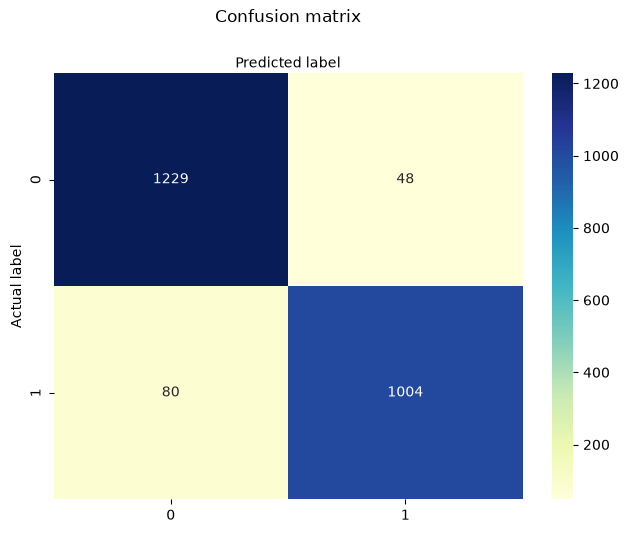

In [20]:
import seaborn as sns
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
